In [1]:
from pyMoove import io, plotting, calculations

from scripts.zone_info import get_zone_info
from pathlib import Path

# Resolve data directory (works from project root or scripts directory)
DATA_DIR = Path("data")


In [2]:

data = io.load_processed_dataset(DATA_DIR)


Loaded dataset in folder: data
  positions Memory: 571.74 MiB
  feeding Memory: 0.28 MiB
  replacements Memory: 0.02 MiB
Total memory: 572.05 MiB



In [3]:
zones_path = DATA_DIR / "zone_info.csv"
zones = get_zone_info(zones_path)

In [4]:

# Calculate statistics for all feeding bins
#bins = sorted(data["feeding"]["bin"].dropna().unique())
#bin_statistics = calculations.calculate_bin_position_statistics(data, bins, outlier_confidence=0.9999)

# Save results to Parquet
bin_statistics_path = DATA_DIR / "bin_position_stats.parquet"
#bin_statistics.to_parquet(bin_statistics_path, index=False)

bin_statistics = io.load_bin_stats_parquet(bin_statistics_path)
#bin_statistics

In [ ]:
bins = range(1,59)
plotting.plot_bins(zones, bin_statistics, bins)


--- Feeding Events at Bin 58 ---
Total feeding visits: 25
Unique cows:          13
Total feeding time:   14,898 s (248.3 min)
Total position fixes: 7462
Retained fixes:       4171 (3291 flagged as outliers; confidence=100.0%)
Filtered centroid:    x = 218.21 m (std 0.44), y = 22.96 m (std 0.54)


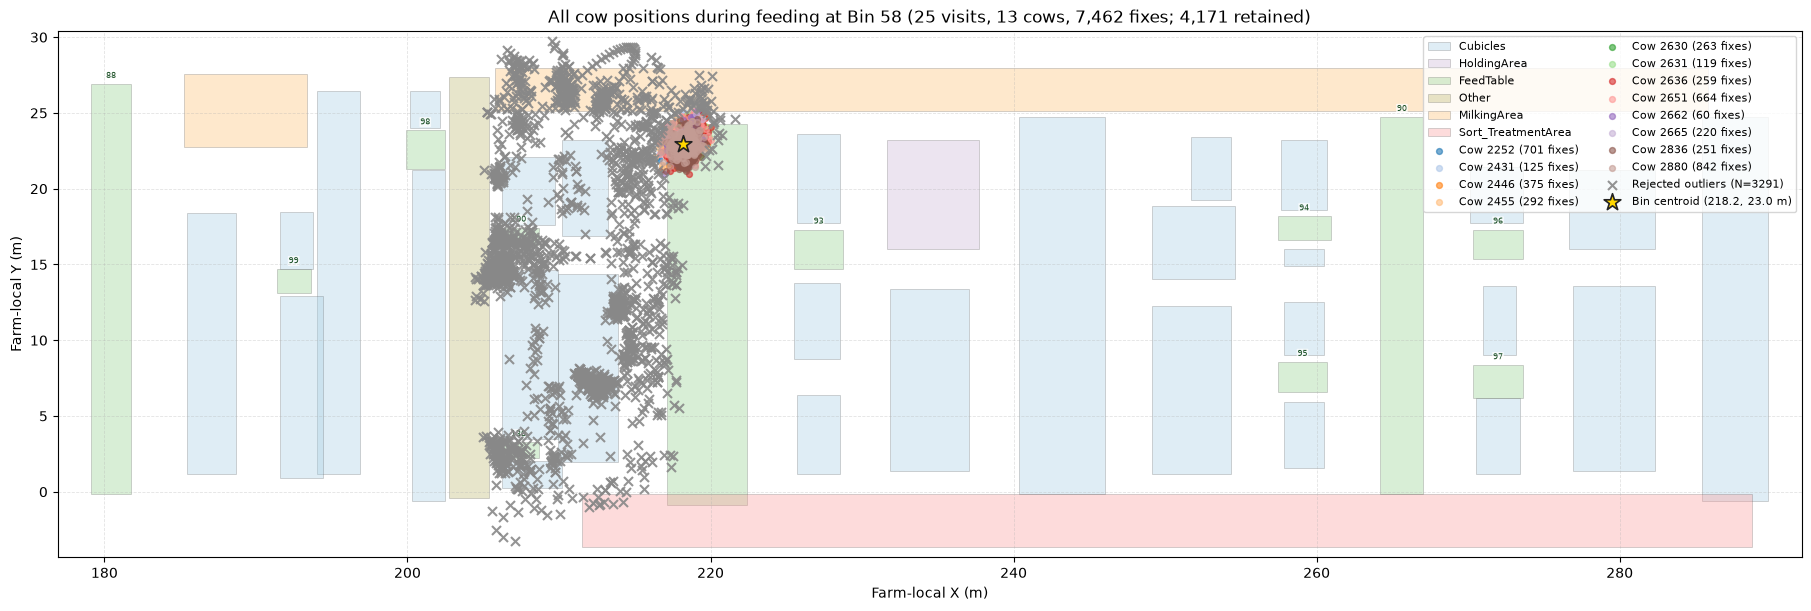

In [ ]:

# Option A: Plot all feeding events for a specific bin (e.g. Bin 21, 24, etc.)
bins = range(58, 59)
for i in bins:
    target_bin = i
    fig, ax = plotting.plot_bin_feeding_positions(data, zones, bin_id=target_bin, color_by_cow=True, filter_outliers=True, outlier_confidence=0.9999)

# Option B: Plot a single feeding event by index (uncomment to use):
# fig, ax = plot_feeding_event(data, zones, event_index=0)

In [ ]:

animations = []
for i in range(40, 41):
    fig, ax, animation = plotting.plot_replacement_example(data, zones=zones, bin_statistics=bin_statistics, event_index=i, animate=True, relative_start_time=60)
    animations.append(animation)